# 07 · RDMs clustered within CDI domains, any datasets

**What it does.** For any 2+ of `bv vedb things imagenet lvis`, on the categories they all share (ImageNet / LVIS:
their exclusive sets), each re-z-scored on that set:
- every pair's RDM Spearman, permutation p and bootstrap CI;
- with BV and 2+ others: bootstrap CI of ρ(BV, X) − ρ(BV, Y);
- one RDM panel per dataset in CDI-domain blocks, ordered within domain alphabetically or by average-linkage
  clustering (optimal leaf ordering) on **one reference RDM shared by all panels**, one figure per reference
  (the reference dataset always looks most block-structured).

**Outputs:** `outputs/rdms/<datasets>/results/` and `figures/`.

In [1]:
# Standard setup shared by every notebook (each notebook is self-contained).
import json
import os
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage, optimal_leaf_ordering
from scipy.spatial.distance import pdist, squareform
from scipy.stats import false_discovery_control, pearsonr, rankdata, spearmanr, wilcoxon
from IPython.display import Image, Markdown, display

plt.rcParams["font.family"] = ["DejaVu Sans", "sans-serif"]
pd.set_option("display.max_colwidth", 120)


def show_images(paths, width=950):
    """Display saved figures (the files this notebook writes)."""
    for p in map(Path, paths):
        if p.exists():
            display(Markdown(f"`{p.relative_to(ROOT)}`")); display(Image(filename=str(p), width=width))
        else:
            display(Markdown(f"*Missing figure:* `{p}`"))

In [2]:
# Paths. Run this notebook from analysis/comparison-datasets/notebooks/ (Jupyter's default working directory).
ROOT = Path.cwd().resolve().parent                     # analysis/comparison-datasets
assert (ROOT / "notebooks").is_dir(), "open this notebook from analysis/comparison-datasets/notebooks/"
REPO = ROOT.parents[1]
DATA_DIR = REPO / "data"
MANUSCRIPT_DIR = REPO / "analysis" / "manuscript-2026"
VEDB_DIR = REPO / "analysis" / "vedb-1612"
VOCAB_DIR = DATA_DIR / "vocabulary_lists"
VALID129_TXT = VOCAB_DIR / "included_categories_valid129.txt"

# Inputs written by other pipelines (read only).
EXEMPLAR_EMBED_ROOT = Path(os.environ.get("BV_EXEMPLAR_EMBED_ROOT",
                                          str(MANUSCRIPT_DIR / "exemplar_set_embeddings"))).expanduser()
BV_THINGS_VALID129 = EXEMPLAR_EMBED_ROOT / "valid129"       # manuscript Stage 0: BV + THINGS tables
VEDB_VALID129 = VEDB_DIR / "exemplar_set_embeddings" / "valid129"   # vedb-1612 Stage 0 (files use the "bv_" prefix)

# External data on ccn2.
IMAGENET_DIR = Path("/data2/j7yang/imagenet-1k/extracted")
IMAGENET_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/imagenet_1k/outputs/image_embeddings")
LVIS_ROOT = Path("/data2/j7yang/lvis")
LVIS_CROP_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/lvis/outputs/crop_embeddings")

# Outputs of this folder.
OUT = ROOT / "outputs"
MAPPING_OUT = OUT / "mapping"
MONTAGE_OUT = OUT / "montages"
EXEMPLAR_SETS = OUT / "exemplar_sets"
MODELS = ("clip", "dinov3")

## Parameters
Any 2+ of `bv vedb things imagenet lvis`.

In [3]:
DATASETS = ["bv", "vedb", "lvis"]

_allowed = ('bv', 'vedb', 'things', 'imagenet', 'lvis')
assert set(DATASETS) <= set(_allowed) and len(set(DATASETS)) >= 2, f"DATASETS must be 2+ of {_allowed}"
DATASETS = [d for d in _allowed if d in DATASETS]   # fixed display order

## Shared helpers

In [4]:
def load_cdi_semantic_map() -> dict[str, str]:
    """``uni_lemma`` → CDI semantic domain from ``data/cdi_words.csv``.

    Frequency tables under ``data/long_tailed_dist_prop_included_categories_*.csv``
    are not a semantic source: the unfiltered valid129 file currently copies
    valid85 labels and marks the extra 44 categories as ``other``.
    """
    import pandas as pd

    path = DATA_DIR / "cdi_words.csv"
    df = pd.read_csv(path, usecols=["uni_lemma", "category"])
    df["uni_lemma"] = df["uni_lemma"].astype(str).str.strip().str.lower()
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return (
        df.drop_duplicates(subset=["uni_lemma"], keep="first")
        .set_index("uni_lemma")["category"]
        .to_dict()
    )


# Dataset registry and raw-table loading (shared helpers; repeated in each notebook that needs them).
ALL_DATASETS = ("bv", "vedb", "things", "imagenet", "lvis")
LABEL = {"bv": "BV", "vedb": "VEDB", "things": "THINGS", "imagenet": "ImageNet", "lvis": "LVIS"}
COLOR = {"bv": "#90caf9", "vedb": "#0d47a1", "imagenet": "#eb6834", "lvis": "#1baf7a", "things": "#eda100"}
COMPARISON_SETS = {"imagenet": "imagenet_exclusive75", "lvis": "lvis_exclusive104"}


def zscore_rows(X: np.ndarray, eps: float = 1e-10) -> np.ndarray:
    """Same as manuscript notebook 07: z-score each dimension across categories."""
    return (X - X.mean(axis=0)) / (X.std(axis=0) + eps)


def raw_path(ds: str, model: str) -> Path:
    if ds in COMPARISON_SETS:
        s = COMPARISON_SETS[ds]
        return EXEMPLAR_SETS / s / f"{ds}_{model}_exemplar_avg_raw_within_{s}.csv"
    if ds == "vedb":
        return VEDB_VALID129 / f"bv_{model}_exemplar_avg_raw_within_valid129.csv"
    return BV_THINGS_VALID129 / f"{ds}_{model}_exemplar_avg_raw_within_valid129.csv"


def load_raw(path: Path, cats: list[str]) -> np.ndarray:
    df = pd.read_csv(path)
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return df.set_index("category").loc[cats].filter(like="dim_").to_numpy(dtype=np.float64)


def shared_categories(datasets) -> list[str]:
    """Categories present in every given dataset's table, for both models (sorted)."""
    present = None
    for ds in datasets:
        for model in MODELS:
            cats = set(pd.read_csv(raw_path(ds, model), usecols=["category"])["category"].str.strip().str.lower())
            present = cats if present is None else present & cats
    return sorted(present)


def zscored_tables(datasets, cats, model) -> dict[str, np.ndarray]:
    """{dataset: category x dim matrix}, each z-scored within cats."""
    return {ds: zscore_rows(load_raw(raw_path(ds, model), cats)) for ds in datasets}

In [5]:
CDI_SEMANTIC_COLORS = {  # same as notebook 03
    "animals": "#4DB8A8", "body_parts": "#E87A5F", "clothing": "#9B7EC8",
    "food_drink": "#E8A54C", "furniture_rooms": "#6BAB7A", "household": "#D97B9E",
    "outside": "#5B9BD5", "toys": "#B07CC8", "vehicles": "#6BA3D5", "other": "#8B9A9E",
}
CDI_SEMANTIC_ORDER = ["animals", "body_parts", "clothing", "food_drink", "furniture_rooms",
                      "household", "outside", "toys", "vehicles", "other"]
N_PERM = int(os.environ.get("BV_RDM_BASELINE_N_PERM", "5000"))
N_BOOT = int(os.environ.get("BV_RDM_N_BOOT", "2000"))
SEED = int(os.environ.get("BV_RDM_BASELINE_SEED", "2026"))


def semantic_order(cats: list[str], sem: dict[str, str], ref_rdm: np.ndarray | None = None
                   ) -> tuple[np.ndarray, list[str]]:
    """Indices ordering categories by CDI domain (fixed order). Within a domain:
    alphabetical (as in notebook 03) if ref_rdm is None, else average-linkage
    hierarchical clustering on ref_rdm's within-domain block with optimal leaf ordering."""
    labels = [sem.get(c, "other") if sem.get(c, "other") in CDI_SEMANTIC_ORDER else "other" for c in cats]
    order: list[int] = []
    for dom in CDI_SEMANTIC_ORDER:
        idx = sorted((i for i in range(len(cats)) if labels[i] == dom), key=lambda i: cats[i])
        if ref_rdm is not None and len(idx) > 2:
            sub = ref_rdm[np.ix_(idx, idx)]
            Z = optimal_leaf_ordering(linkage(squareform(sub, checks=False), method="average"),
                                      squareform(sub, checks=False))
            idx = [idx[k] for k in leaves_list(Z)]
        order.extend(idx)
    return np.array(order), [labels[i] for i in order]


def upper(rdm: np.ndarray) -> np.ndarray:
    return rdm[np.triu_indices_from(rdm, k=1)]


def perm_p_spearman(rdm_a: np.ndarray, rdm_b: np.ndarray, observed: float, rng) -> tuple[float, float]:
    """One-sided p for Spearman(rdm_a, rdm_b) under shuffling rdm_b's category labels."""
    n = rdm_a.shape[0]
    iu = np.triu_indices(n, k=1)
    ra = rankdata(rdm_a[iu])
    ra = (ra - ra.mean()) / ra.std()
    null = np.empty(N_PERM)
    for k in range(N_PERM):
        p = rng.permutation(n)
        rb = rankdata(rdm_b[np.ix_(p, p)][iu])
        null[k] = np.mean(ra * (rb - rb.mean()) / rb.std())
    return float((np.sum(null >= observed) + 1) / (N_PERM + 1)), float(null.mean())

## RDM bootstrap, figure and analysis

In [6]:
N_BOOT = 2000


def bootstrap(rdms: dict, datasets, pairs, rng) -> dict:
    """Resample categories; drop pairs that are the same original category."""
    n = rdms[datasets[0]].shape[0]
    iu = np.triu_indices(n, k=1)
    out = {p: np.empty(N_BOOT) for p in pairs}
    for k in range(N_BOOT):
        idx = rng.integers(0, n, n)
        keep = idx[iu[0]] != idx[iu[1]]
        v = {ds: rdms[ds][np.ix_(idx, idx)][iu][keep] for ds in datasets}
        for a, b in pairs:
            out[(a, b)][k] = spearmanr(v[a], v[b])[0]
    return out


def plot(model, tag, datasets, cats, rdms, order, sem_labels, rho, ref, out_dir):
    n, k = len(cats), len(datasets)
    fig, axes = plt.subplots(1, k, figsize=(5.7 * k, 6.4), constrained_layout=True, squeeze=False)
    axes = axes[0]
    bounds = [i for i in range(1, n) if sem_labels[i] != sem_labels[i - 1]]
    starts, ends = [0] + bounds, bounds + [n]
    for j, (ax, ds) in enumerate(zip(axes, datasets)):
        im = ax.imshow(rdms[ds][np.ix_(order, order)], cmap="viridis", vmin=0, vmax=2)
        for b in bounds:
            ax.axhline(b - 0.5, color="white", lw=0.8)
            ax.axvline(b - 0.5, color="white", lw=0.8)
        vs = ", ".join(f"ρ {LABEL[e]} = {rho[(e, ds)]:.2f}" for e in datasets[:j])
        ax.set_title(LABEL[ds] + (f"   ({vs})" if vs else ""), fontsize=11)
        ax.set_yticks([])
        ax.set_xticks([(s + e - 1) / 2 for s, e in zip(starts, ends)])
        ax.set_xticklabels([sem_labels[s].replace("_", " ") for s in starts], rotation=45, ha="right", fontsize=7.5)
        ax.tick_params(axis="x", length=0)
        for tick, s in zip(ax.get_xticklabels(), starts):
            tick.set_color(CDI_SEMANTIC_COLORS.get(sem_labels[s], CDI_SEMANTIC_COLORS["other"]))
    axes[0].set_yticks(np.arange(n))
    axes[0].set_yticklabels([cats[i] for i in order], fontsize=4.6)
    axes[0].tick_params(axis="y", length=0, pad=1)
    for tick, lab in zip(axes[0].get_yticklabels(), sem_labels):
        tick.set_color(CDI_SEMANTIC_COLORS.get(lab, CDI_SEMANTIC_COLORS["other"]))
    fig.colorbar(im, ax=list(axes), fraction=0.02, pad=0.01, label="cosine distance")
    how = "alphabetical" if ref is None else f"clustered on {LABEL[ref]} RDM"
    fig.suptitle(f"{model.upper()} category RDMs: {' vs '.join(LABEL[d] for d in datasets)}, CDI domains, {how} "
                 f"within domain (n={n} shared categories; ρ = RDM Spearman)", fontsize=12)
    stem = out_dir / f"rdms_{model}_{tag}_{'alpha' if ref is None else 'clustered_' + ref}"
    fig.savefig(f"{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    plt.close(fig)


def rdms_clustered(datasets, seed: int = 2026):
    """RDMs, pairwise RDM correlations and within-domain-clustered figures for the given datasets;
    write results and figures; return {"correlations": table, "summary": text, "categories": list}."""
    datasets = [d for d in ALL_DATASETS if d in datasets]  # fixed display order
    tag = "_".join(datasets)
    pairs = list(combinations(datasets, 2))
    sem = load_cdi_semantic_map()
    cats = shared_categories(datasets)
    out = OUT / "rdms" / tag
    (out / "results").mkdir(parents=True, exist_ok=True)
    (out / "figures").mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)

    rows, lines = [], [f"{' vs '.join(LABEL[d] for d in datasets)} RDMs (n={len(cats)} shared categories)\n"]
    for model in MODELS:
        X = zscored_tables(datasets, cats, model)
        rdms = {ds: squareform(pdist(X[ds], metric="cosine")) for ds in datasets}
        boot = bootstrap(rdms, datasets, pairs, rng)
        rho = {}
        lines.append(f"{model}:")
        for a, b in pairs:
            va, vb = upper(rdms[a]), upper(rdms[b])
            sr = spearmanr(va, vb)[0]
            rho[(a, b)] = sr
            p_perm, null_mean = perm_p_spearman(rdms[a], rdms[b], sr, rng)
            lo, hi = np.percentile(boot[(a, b)], [2.5, 97.5])
            rows.append({"model": model, "dataset_a": a, "dataset_b": b, "n_categories": len(cats),
                         "n_pairs": len(va), "spearman_r": sr, "pearson_r": pearsonr(va, vb)[0],
                         "perm_p_spearman": p_perm, "perm_null_mean_spearman": null_mean,
                         "boot_ci_lo": lo, "boot_ci_hi": hi})
            lines.append(f"  {LABEL[a]}-{LABEL[b]}: Spearman={sr:.3f} [{lo:.3f}, {hi:.3f}], perm p={p_perm:.4f}")
        others = [d for d in datasets if d != "bv"]
        if "bv" in datasets:
            for x, y in combinations(others, 2):
                diff = boot[("bv", x)] - boot[("bv", y)]
                dlo, dhi = np.percentile(diff, [2.5, 97.5])
                d_obs = rho[("bv", x)] - rho[("bv", y)]
                rows.append({"model": model, "dataset_a": f"bv-{x}", "dataset_b": f"minus bv-{y}",
                             "n_categories": len(cats), "spearman_r": d_obs, "boot_ci_lo": dlo, "boot_ci_hi": dhi})
                lines.append(f"  rho(BV-{LABEL[x]}) - rho(BV-{LABEL[y]}) = {d_obs:.3f} [{dlo:.3f}, {dhi:.3f}]")

        for ref in (None, *datasets):
            order, sem_labels = semantic_order(cats, sem, None if ref is None else rdms[ref])
            plot(model, tag, datasets, cats, rdms, order, sem_labels, rho, ref, out / "figures")

    table = pd.DataFrame(rows)
    table.to_csv(out / "results" / f"rdm_correlations_{tag}.csv", index=False)
    text = "\n".join(lines)
    (out / "results" / f"rdm_summary_{tag}.txt").write_text(text + "\n")
    print(text)
    return {"correlations": table, "summary": text, "categories": cats}

## Run (~1 min)

In [7]:
res = rdms_clustered(DATASETS)
res['correlations'].round(3)

BV vs VEDB vs LVIS RDMs (n=104 shared categories)

clip:
  BV-VEDB: Spearman=0.814 [0.766, 0.854], perm p=0.0002
  BV-LVIS: Spearman=0.486 [0.393, 0.580], perm p=0.0002
  VEDB-LVIS: Spearman=0.484 [0.402, 0.562], perm p=0.0002
  rho(BV-VEDB) - rho(BV-LVIS) = 0.329 [0.241, 0.416]
dinov3:
  BV-VEDB: Spearman=0.778 [0.731, 0.820], perm p=0.0002
  BV-LVIS: Spearman=0.530 [0.461, 0.600], perm p=0.0002
  VEDB-LVIS: Spearman=0.495 [0.427, 0.565], perm p=0.0002
  rho(BV-VEDB) - rho(BV-LVIS) = 0.247 [0.168, 0.322]


,model,dataset_a,dataset_b,n_categories,n_pairs,spearman_r,pearson_r,perm_p_spearman,perm_null_mean_spearman,boot_ci_lo,boot_ci_hi
0,clip,bv,vedb,104,5356.0,0.814,0.852,0.0,0.0,0.766,0.854
1,clip,bv,lvis,104,5356.0,0.486,0.531,0.0,-0.0,0.393,0.580
2,clip,vedb,lvis,104,5356.0,0.484,0.518,0.0,-0.0,0.402,0.562
3,clip,bv-vedb,minus bv-lvis,104,NaN,0.329,NaN,NaN,NaN,0.241,0.416
4,dinov3,bv,vedb,104,5356.0,0.778,0.815,0.0,0.0,0.731,0.820
5,dinov3,bv,lvis,104,5356.0,0.530,0.605,0.0,0.0,0.461,0.600
6,dinov3,vedb,lvis,104,5356.0,0.495,0.575,0.0,-0.0,0.427,0.565
7,dinov3,bv-vedb,minus bv-lvis,104,NaN,0.247,NaN,NaN,NaN,0.168,0.322


## Figures (clustered on BV; other orderings are saved alongside)

`outputs/rdms/bv_vedb_lvis/figures/rdms_clip_bv_vedb_lvis_clustered_bv.png`

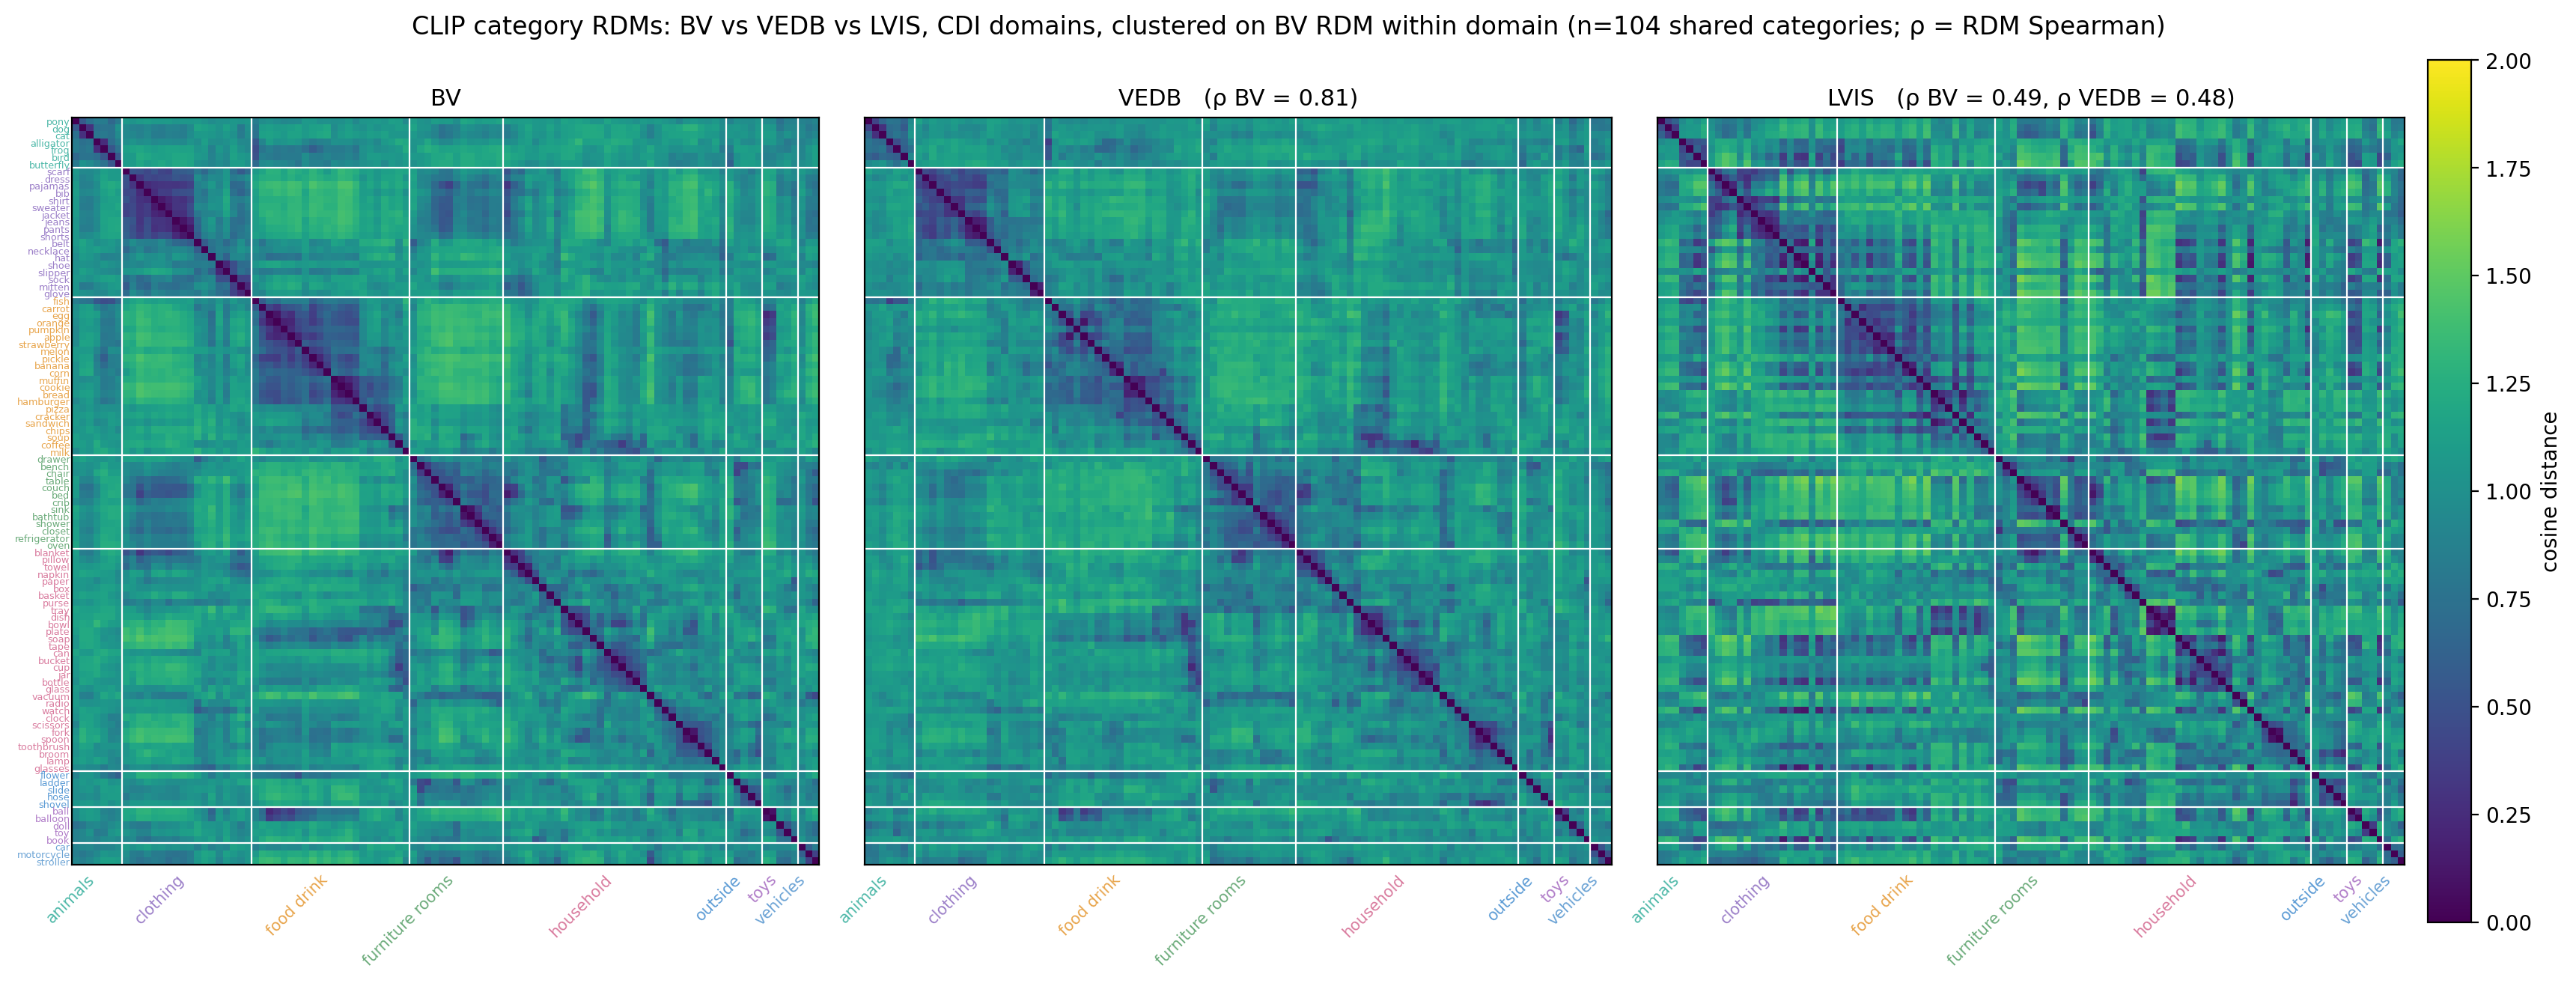

`outputs/rdms/bv_vedb_lvis/figures/rdms_dinov3_bv_vedb_lvis_clustered_bv.png`

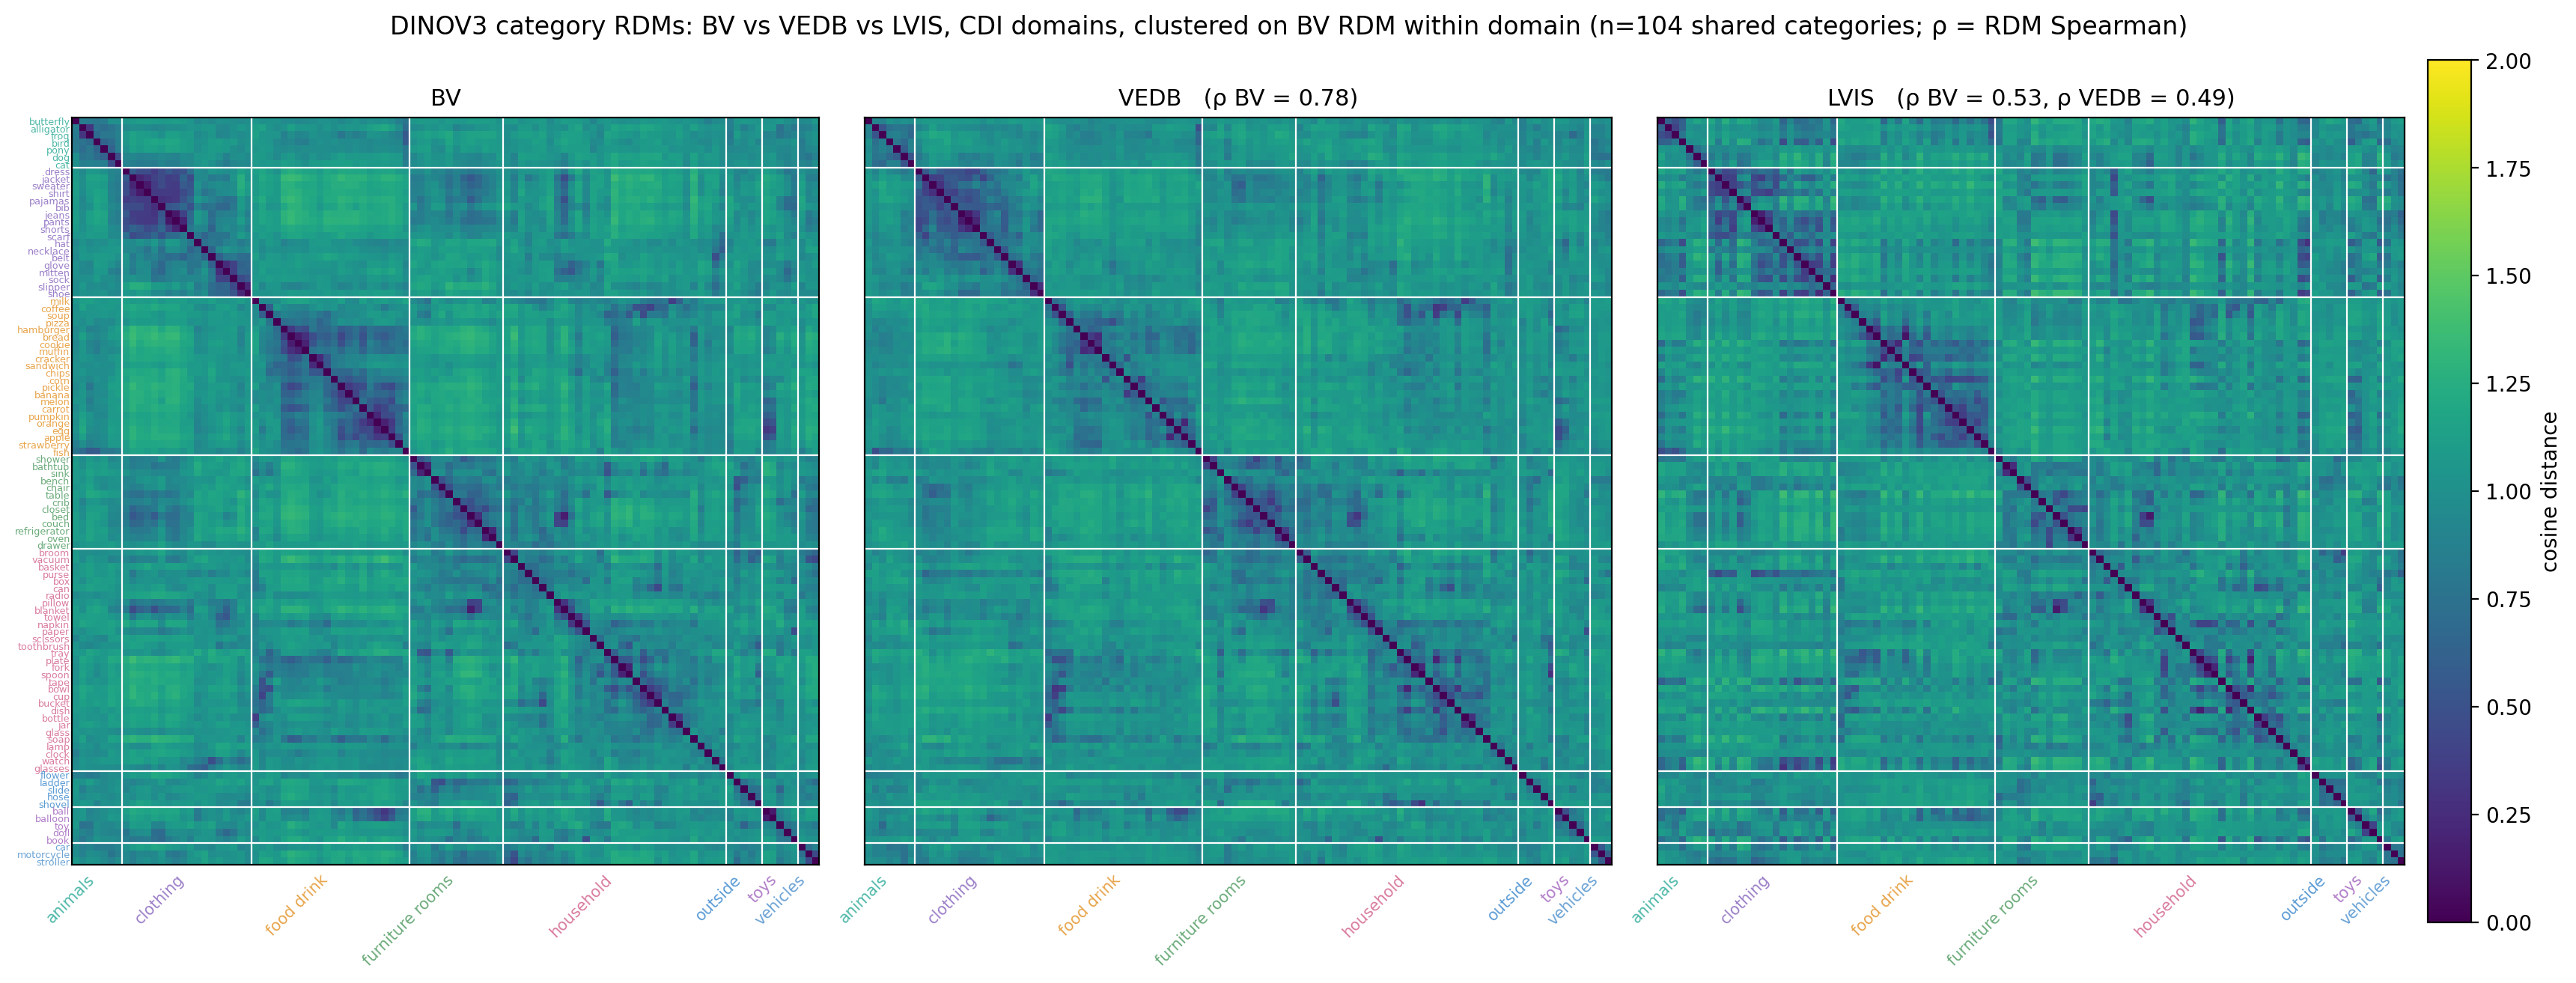

In [8]:
t = "_".join(DATASETS)
ref = "bv" if "bv" in DATASETS else DATASETS[0]
show_images([OUT / "rdms" / t / "figures" / f"rdms_{m}_{t}_clustered_{ref}.png" for m in MODELS])

### Review checklist

- Are all panels drawn in one shared order?
- Is the shared category set what you expect (`res['categories']`)?